# B03 — Paleobathymetry profile across the Atlantic at 50 Ma


**Cluster B: Plate kinematics + tectonics.**
**Half-space cooling, applied to a reconstructed age grid, is paleo-*basement* depth — not true paleobathymetry.** True paleobathymetry would require adding the sediment column on top of the basement; the half-space cooling relation of Parsons & Sclater (1977) gives only the top of the oceanic crust as a function of age.

## What this notebook produces

A single chart panel showing a **long bathymetric profile** from the paleo-position of New York to the paleo-position of Lisbon at 50 Ma. The profile follows the great circle between the two reconstructed end points and is extracted from a paleo-depth grid built by feeding the Zahirovic 2022 reconstructed age grid through the half-space cooling relation of Parsons & Sclater (1977).

**Audience**: postgraduate / honours.  
**Difficulty**: ★★★.

## Learning objectives

- Sample a paleo-bathymetry raster along a great-circle profile across the central Atlantic.
- Reconstruct the profile endpoints to 50 Ma so the profile follows the paleo-margin, not the present-day one.
- Render the profile as a pyGMT cross-section, with distance in km, and an inset map of the transect.


## Prerequisites and runtime

- **Plate model**: Zahirovic 2022.
- **Time**: 50 Ma.
- **Python**: `gplately`, `pygmt`, `pygplates`, `numpy`, `pandas`, `xarray`.
- **Runtime**: \~1 minute.


In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import numpy as np, pandas as pd, xarray as xr, gplately, pygmt
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
from IPython.display import display, HTML

# Library versions (printed for reproducibility)
try:
    import gplately, pygmt, pygplates
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0  pygmt v0.19.0  pygplates 1.0.0


## Configuration

User-tunable choices for this notebook. Edit the values below to change the model, snapshot time, region, or anchor plate without hunting through downstream code.


In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME           = "Zahirovic2022"
RECONSTRUCTION_TIME  = 50.0          # Ma — the Atlantic in the early Eocene
ANCHOR_PLATE_ID      = 0             # 0 = mantle reference frame
PROFILE_START        = (-74.0, 40.7)  # (lon, lat) of the start point today — New York (North American plate)
PROFILE_END          = (-9.1, 38.7)   # (lon, lat) of the end point today — Lisbon (Iberia)
PROFILE_STEP_KM      = 10.0          # sample spacing along the profile (km)
# ============================================================================


In [3]:
# Cell 2 — load plate model + reconstruct profile endpoints
#
# Note on the unpacking order below: gplately's `Points.reconstruct(time,
# return_array=True)` returns *longitudes first*, then latitudes — the
# opposite of what the variable names might suggest at a glance. Unpacking
# the other way around is a silent bug (the profile renders in the wrong
# place). Reversing the unpacking silently mis-plots — mixing this up
# is a common GPlately pitfall.
T = RECONSTRUCTION_TIME
pmm = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="./gplately_data")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
    anchor_plate_id=ANCHOR_PLATE_ID,
)

# The two end points, as they are today; GPlately assigns each the plate ID of the
# static polygon it falls in, then reconstructs both to T Ma.
ENDS = gplately.Points(plate_reconstruction=recon,
                        lons=[PROFILE_START[0], PROFILE_END[0]],
                        lats=[PROFILE_START[1], PROFILE_END[1]])
end_lons, end_lats = ENDS.reconstruct(time=T, return_array=True)  # longitudes first per gplately convention
for name, pid, lo, la in zip(("start", "end"), ENDS.plate_id, end_lons, end_lats):
    print(f"Profile {name} (plate {pid}) at {T:.0f} Ma: ({la:.1f}°N, {lo:.1f}°E)")


Profile start (plate 101) at 50 Ma: (41.1°N, -60.6°E)
Profile end (plate 304) at 50 Ma: (36.4°N, -11.6°E)


In [4]:
# Cell 3 — load age grid → paleo-basement depth (sediment-free)
# Half-space cooling (Parsons & Sclater 1977): depth = 2500 m + 350 m * sqrt(age in Myr).
age_file = model.get_raster("AgeGrids", time=T)
age_da = xr.open_dataarray(age_file) if str(age_file).endswith(".nc") \
         else xr.open_dataset(age_file).to_array().isel(variable=0)

def age_to_depth(a): return -(2500 + 350 * np.sqrt(np.clip(a, 0, None)))
depth_da = xr.apply_ufunc(age_to_depth, age_da)

### What the profile shows

Read the profile from left to right, from the reconstructed position of New York towards that of Lisbon. The first part of the transect crosses North American continental crust, which has no seafloor age and is left blank. The ocean floor begins with the deepest basement of the profile, about 6.5 km below sea level: the oldest crust of the central Atlantic, formed in the Jurassic soon after the Atlantic began to open. Towards the east the crust becomes younger and shallower up to the **mid-Atlantic ridge** at about 3,100 km, where zero-age crust lies about 2.7 km below sea level. East of the ridge the basement deepens again towards Iberia, to about 5.5 km.

The two flanks are not mirror images. The crust next to North America is older than the crust next to Iberia, because the central Atlantic opened long before the ocean between Newfoundland and Iberia, and the transect crosses fracture zones obliquely, which produces the steps in the western flank. The half-space relation also deepens without limit as the crust ages, so it overestimates the depth of the oldest crust compared with plate-cooling models (see Extend this).

Profile: 4228 km long; 204 of 424 samples on oceanic crust


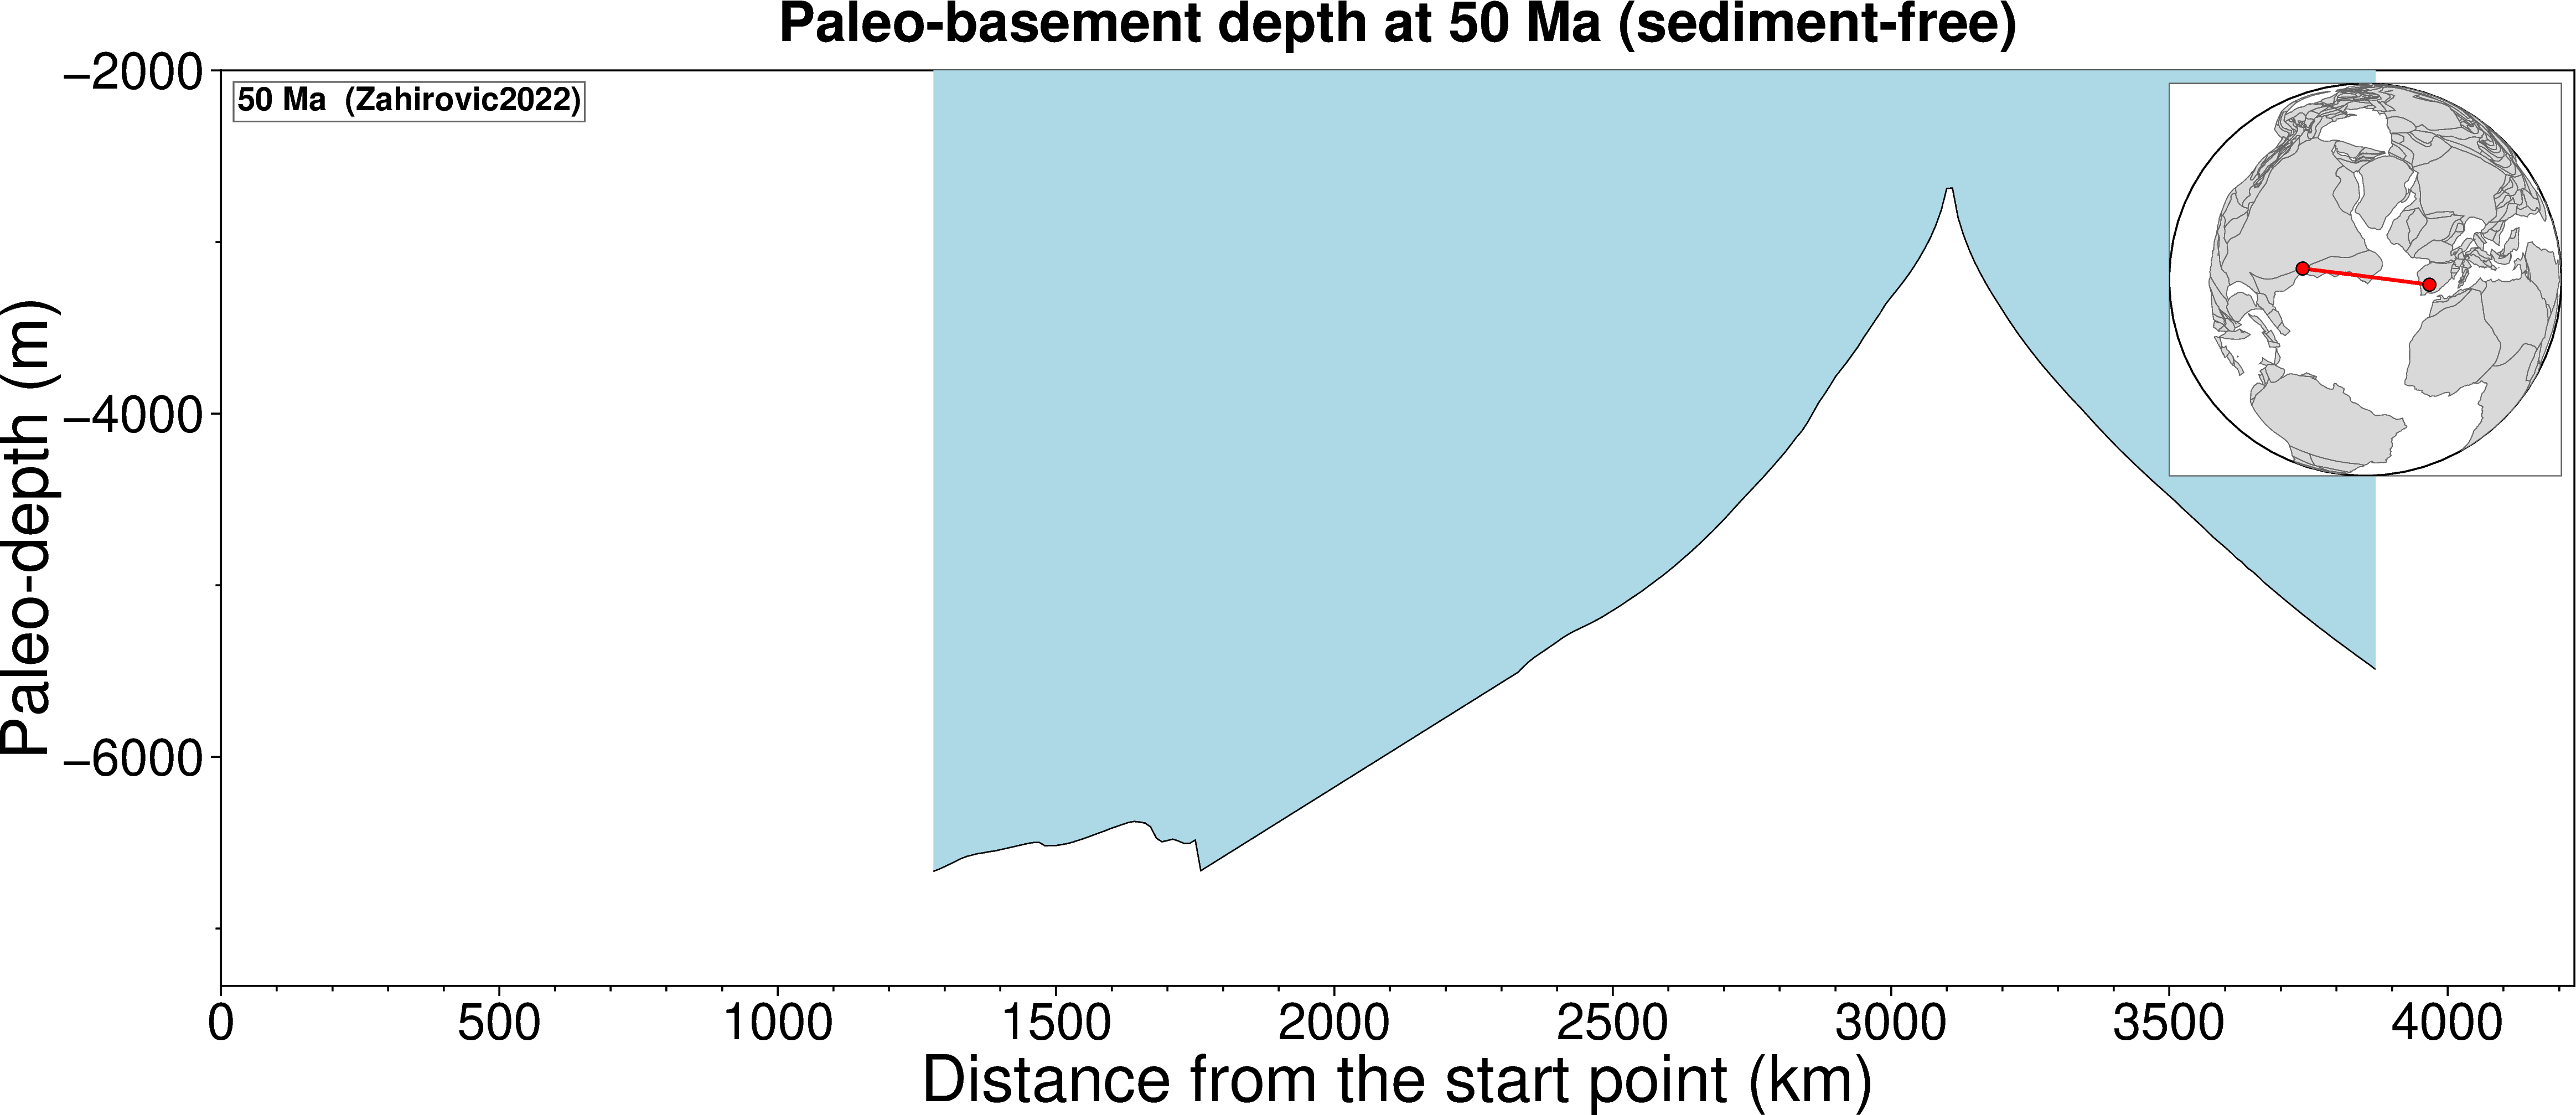

In [5]:
# Cell 4 — profile along the great circle between the reconstructed end points
#
# pygmt.project generates points every PROFILE_STEP_KM km along the great circle
# (column "p" is the distance from the start in km); grdtrack samples the
# paleo-depth grid at those points. A named DataFrame keeps grdtrack's
# `newcolname` working.
track = pygmt.project(center=[end_lons[0], end_lats[0]],
                      endpoint=[end_lons[1], end_lats[1]],
                      generate=PROFILE_STEP_KM, unit=True)
pts = pd.DataFrame({"lon": track["r"].to_numpy(), "lat": track["s"].to_numpy(),
                    "dist_km": track["p"].to_numpy()})
profile_track = pygmt.grdtrack(points=pts, grid=depth_da, newcolname="depth")

# Samples on continental crust (no age, NaN depth) are left out of the ocean profile.
profile_clean = profile_track.dropna(subset=["depth"]).reset_index(drop=True)
print(f"Profile: {pts['dist_km'].iloc[-1]:.0f} km long; {len(profile_clean)} of {len(profile_track)} "
      f"samples on oceanic crust")

fig = pygmt.Figure()
# Bump axis-label and tick-label fonts well above the suite default —
# at 36 cm wide they look tiny otherwise.
with pygmt.config(FONT_LABEL="28p", FONT_ANNOT_PRIMARY="22p",
                  FONT_TITLE="24p"):
    fig.basemap(
        region=[0, float(pts["dist_km"].iloc[-1]), profile_clean["depth"].min()*1.1, -2000],
        projection="X36c/14c",
        frame=["xaf+lDistance from the start point (km)", "yaf+lPaleo-depth (m)",
               f"WSrt+tPaleo-basement depth at {T:.0f} Ma (sediment-free)"])
fig.plot(x=profile_clean["dist_km"], y=profile_clean["depth"],
         fill="lightblue", close="+yB", pen="0.5p,black")
fig.text(text=f"{RECONSTRUCTION_TIME:.0f} Ma  ({MODEL_NAME})",
         position="TL", offset="0.25c/-0.25c", justify="TL",
         font="14p,Helvetica-Bold,black",
         fill="white", pen="0.6p,gray40")

# Inset map (top-right) showing the paleo-position of the transect
# at age T on the paleogeographic reconstruction, so the reader can see WHERE on
# the globe the depth profile above is sampled.
try:
    _gplot_inset = gplately.PlotTopologies(
        plate_reconstruction=recon,
        coastlines=model.get_coastlines(),
        continents=model.get_continental_polygons(),
        COBs=model.get_COBs(),
        time=float(T),
        plot_engine=gplately.PygmtPlotEngine(),
    )
    _xy_lons = pts["lon"].to_numpy()
    _xy_lats = pts["lat"].to_numpy()
    _mid_lon = float(np.mean(_xy_lons))
    _mid_lat = float(np.mean(_xy_lats))
    with fig.inset(position="jTR+w6c+o0.2c",
                   box="+gwhite+p0.4p,gray40", clearance=0):
        fig.basemap(projection=f"G{_mid_lon}/{_mid_lat}/6c",
                    region="g", frame=["f"])
        try:
            fig.plot(data=_gplot_inset.get_continents(),
                     fill="gray85", pen="0.3p,gray40")
        except Exception:
            pass
        fig.plot(x=_xy_lons, y=_xy_lats, pen="1.5p,red")
        fig.plot(x=[_xy_lons[0], _xy_lons[-1]],
                 y=[_xy_lats[0], _xy_lats[-1]],
                 style="c0.20c", fill="red", pen="0.4p,black")
except Exception as _e:
    print(f"  (inset map skipped: {type(_e).__name__}: {_e})")

fig.show(width=1100)
display(HTML('<div style="height:1cm"></div>'))


## What the figure shows

A bathymetric profile along the great circle between the two reconstructed end points at `RECONSTRUCTION_TIME`, sampled every `PROFILE_STEP_KM` km from the loaded plate model's reconstructed age grid and converted to basement depth with the half-space cooling relation depth = 2500 + 350·√age (metres, age in Myr; Parsons & Sclater 1977). Distance along the transect increases left to right; continental crust has no age and is left blank. The inset shows the transect on the reconstruction.

Look for:

- The shallowest point, at about 2.5 km, which marks the spreading ridge (zero-age crust).
- Basement deepening with distance from the ridge as the crust cools and contracts.
- Asymmetries between the two flanks, which record ridge jumps, changes in spreading rate, or crust of different ages on either side of the ridge.

## Extend this

- **Add sediment cover.** Layer a paleo-sediment-thickness grid on top of the basement to get true paleobathymetry.
- **Different age.** Re-render at 100 Ma (mid-Atlantic opening) or 20 Ma (fully opened) for comparison.
- **Switch cooling model.** Replace the half-space relation with the GDH1 plate-cooling model of Stein & Stein (1992), whose depth flattens for crust older than about 20 Myr, to see how the asymptotic depth limit changes the deep-basin signal.
- **Another ocean.** Change `PROFILE_START` and `PROFILE_END` in the Configuration cell, e.g. to a profile across the South Atlantic from Rio de Janeiro (-43.2, -22.9) to Luanda (13.2, -8.8).

## References

- Mather, B.R., Müller, R.D., Zahirovic, S., Cannon, J., Chin, M., Ilano, L., Wright, N.M., Alfonso, C., Williams, S., Tetley, M. & Merdith, A. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geosci. Data J.* 11, 3-10. https://doi.org/10.1002/gdj3.185
- Parsons, B. & Sclater, J.G. (1977). An analysis of the variation of ocean floor bathymetry and heat flow with age. *Journal of Geophysical Research* 82(5), 803-827. https://doi.org/10.1029/JB082i005p00803
- Stein, C.A. & Stein, S. (1992). A model for the global variation in oceanic depth and heat flow with lithospheric age. *Nature* 359, 123-129. https://doi.org/10.1038/359123a0
- Tian, D., Uieda, L., Leong, W.J., Fröhlich, Y., Schlitzer, W., Grund, M., Jones, M., Toney, L., Yao, J., Magen, Y., Materna, K., Belem, A., Newton, T., Anant, A., Ziebarth, M., Quinn, J., Wessel, P. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochem. Geophys. Geosys.* 20, 5556-5564. https://doi.org/10.1029/2019GC008515

- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371-383. https://doi.org/10.1002/gdj3.146
